# Evaluate the trained models on two test sets

Every model trained on Kaggle (`training_results/split_{pct}/{model}/best.*`) is run on:

| test set | images | ground truth | results folder |
|---|---|---|---|
| **original** | 92, the fixed test split of the panoptic indoor dataset (`training_results/splits.json`) | dataset labels | `evaluation/results_original_test/` |
| **own** | 40 own photos (`test_set/images`) | `test_set/labels` | `evaluation/results_own_test/` |

The protocol is the one used for the Kaggle test metrics: the training code's own predictor, best checkpoint,
pycocotools `segm` evaluation, score >= 0.001, max 100 detections per image. On the original test set the numbers
therefore reproduce `training_results/results.csv` (checked below).

Per model and test set: `split_{pct}/{model}/metrics.json`, `per_class_ap.csv` and `images/` (every test image with
the predicted instance masks drawn, score >= `VIS_THRESH`). Each results folder also has `summary.csv`.

**Mask2Former is not evaluated.** All three runs hit CUDA OOM on the Kaggle T4 after 1 to 4 of their 44 to 174
epochs, so no finished model exists.

**Inputs that are not in the repository** (too large): the dataset in `dataset/` (Kaggle dataset
`jeremymattathiasmboe/panoptic-indoor-dataset-instance-segmentation`) and the checkpoints `best.pt` / `best.pth` from the
Kaggle notebook output, copied to `training_results/split_{pct}/{model}/`.

## 1. Setup

In [1]:
import colorsys, gc, json, shutil, subprocess, sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training" / "src").is_dir())
EVAL_DIR = ROOT / "evaluation"

# rfdetr 1.12.1 needs transformers 5.x, installed next to the environment instead of upgrading it
PYLIB = EVAL_DIR / ".pylib"
OVERLAY = ["rfdetr==1.12.1", "transformers==5.24.0", "huggingface_hub==2.4.0", "tokenizers==0.23.3",
           "supervision==0.32.0", "pycocotools==2.0.11", "httpx2==2.16.2", "httpcore2==2.16.2",
           "truststore==0.10.5", "pyDeprecate==0.9.0", "av==19.0.2", "idna==3.20", "regex==2026.11.23"]
if not (PYLIB / "rfdetr").is_dir():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--target", str(PYLIB), "--no-deps", *OVERLAY],
                   check=True)
sys.path[:0] = [str(PYLIB), str(ROOT / "training" / "src")]

import cv2
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils

import common as C  # training/src: same COCO conversion and evaluator as the Kaggle run
print("torch", torch.__version__, "| cuda", torch.cuda.is_available())

torch 2.14.1+cu130 | cuda True


## 2. Models and settings

In [2]:
CFG = json.loads((ROOT / "training_results" / "exp_config.json").read_text())  # exact Kaggle config
CFG["DATASET_DIR"] = str(ROOT / "dataset")
NAMES = C.class_names(CFG)

MODELS = ["yolo26l_seg", "maskrcnn_r50_fpn", "rfdetr_seg_l"]
SPLITS = CFG["TRAIN_FRACTIONS"]
EXCLUDED = {"mask2former_swin_t": "CUDA OOM on Kaggle T4 after 1 to 4 of 44 to 174 epochs, no finished checkpoint"}
VIS_THRESH = 0.5        # only for the drawn images, metrics use every detection >= SCORE_THRESH
OWN_LONG_SIDE = 1280    # 12 MP photos are evaluated on a resized copy, labels are normalised so they still fit
RERUN = False           # True = recompute results that already exist

TEST_SETS = {
    "original": {"src": Path(CFG["DATASET_DIR"]), "out": EVAL_DIR / "results_original_test"},
    "own": {"src": ROOT / "test_set", "out": EVAL_DIR / "results_own_test"},
}


def weights(model_key, frac):
    d = ROOT / "training_results" / f"split_{C.pct(frac)}" / model_key
    w = next((d / f for f in ("best.pt", "best.pth") if (d / f).exists()), None)
    assert w, f"no best checkpoint in {d.relative_to(ROOT)} (copy it from the Kaggle output)"
    return w


def class_color(c):
    r, g, b = colorsys.hsv_to_rgb((c * 0.618034) % 1.0, 0.75, 1.0)  # golden-ratio hue steps
    return int(b * 255), int(g * 255), int(r * 255)


for k in MODELS:
    for f in SPLITS:
        print(f"{k:18s} split_{C.pct(f):<3d} {weights(k, f).relative_to(ROOT)}")

yolo26l_seg        split_25  training_results/split_25/yolo26l_seg/best.pt
yolo26l_seg        split_50  training_results/split_50/yolo26l_seg/best.pt
yolo26l_seg        split_100 training_results/split_100/yolo26l_seg/best.pt
maskrcnn_r50_fpn   split_25  training_results/split_25/maskrcnn_r50_fpn/best.pt
maskrcnn_r50_fpn   split_50  training_results/split_50/maskrcnn_r50_fpn/best.pt
maskrcnn_r50_fpn   split_100 training_results/split_100/maskrcnn_r50_fpn/best.pt
rfdetr_seg_l       split_25  training_results/split_25/rfdetr_seg_l/best.pth
rfdetr_seg_l       split_50  training_results/split_50/rfdetr_seg_l/best.pth
rfdetr_seg_l       split_100 training_results/split_100/rfdetr_seg_l/best.pth


## 3. Ground truth of both test sets (COCO json)

In [3]:
def resized_copy(src, dst, long_side):
    """Upright (EXIF applied), resized images plus the same normalised labels, so 12 MP photos fit in RAM."""
    for sub in ("images", "labels"):
        (dst / sub).mkdir(parents=True, exist_ok=True)
    for p in sorted(q for q in (src / "images").iterdir() if q.suffix.lower() in C.IMG_EXTS):
        out = dst / "images" / p.name
        if not out.exists():
            im = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
            s = long_side / max(im.size)
            if s < 1:
                im = im.resize((round(im.width * s), round(im.height * s)), Image.Resampling.BILINEAR)
            im.save(out, format="JPEG", quality=95)
        shutil.copy2(src / "labels" / f"{p.stem}.txt", dst / "labels" / f"{p.stem}.txt")  # always fresh labels
    shutil.copy2(src / "data.yaml", dst / "data.yaml")
    return dst


TEST_SETS["original"]["dir"] = TEST_SETS["original"]["src"]
TEST_SETS["original"]["files"] = json.loads((ROOT / "training_results" / "splits.json").read_text())["test"]
TEST_SETS["own"]["dir"] = resized_copy(TEST_SETS["own"]["src"], EVAL_DIR / ".cache" / f"own_{OWN_LONG_SIDE}",
                                       OWN_LONG_SIDE)
TEST_SETS["own"]["files"] = sorted(p.name for p in (TEST_SETS["own"]["dir"] / "images").iterdir())
assert C.class_names({"DATASET_DIR": TEST_SETS["own"]["dir"]}) == NAMES, "test_set/data.yaml classes differ"

for name, ts in TEST_SETS.items():
    ts["out"].mkdir(parents=True, exist_ok=True)
    gt = C.yolo_to_coco({"DATASET_DIR": ts["dir"]}, ts["files"], NAMES)
    ts["gt"] = ts["out"] / "ground_truth_coco.json"
    ts["gt"].write_text(json.dumps(gt))
    ts["img_dir"] = ts["dir"] / "images"
    n_cls = len({a["category_id"] for a in gt["annotations"]})
    print(f"{name:8s} {len(gt['images'])} images, {len(gt['annotations'])} instances, {n_cls} classes "
          f"-> {ts['out'].relative_to(ROOT)}")

original 92 images, 1123 instances, 68 classes -> evaluation/results_original_test
own      40 images, 384 instances, 39 classes -> evaluation/results_own_test


## 4. Predictors (same code as the Kaggle test evaluation)

In [4]:
def load_predictor(model_key, frac):
    """The training code's own test-time predictor, loaded from the best checkpoint.
    predict(path) -> [{"category_id", "score", "mask": bool HxW at the image's resolution}]"""
    hp, w = CFG["MODELS"][model_key], weights(model_key, frac)
    if hp["impl"] == "yolo":  # training/src/train_yolo.py run()
        from ultralytics import YOLO
        model = YOLO(str(w))

        def predict(path):
            r = model.predict(str(path), imgsz=CFG["IMG_SIZE"], conf=CFG["SCORE_THRESH"], max_det=CFG["MAX_DET"],
                              retina_masks=True, half=CFG["AMP"], device=0, verbose=False)[0]
            if r.masks is None:
                return []
            masks = (r.masks.data > 0.5).cpu().numpy()
            return [{"category_id": int(c) + 1, "score": float(s), "mask": masks[i]}
                    for i, (c, s) in enumerate(zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()))]
        return predict, model

    if hp["impl"] == "maskrcnn":  # training/src/train_maskrcnn.py MaskRCNNAdapter
        import train_maskrcnn
        adapter = train_maskrcnn.MaskRCNNAdapter(CFG, hp)
        model = adapter.build()
        model.load_state_dict(torch.load(w, map_location="cpu", weights_only=False)["model"])
        model.to("cuda").eval()
        return adapter.predictor(model, torch.device("cuda")), model

    if hp["impl"] == "rfdetr":  # training/src/train_rfdetr.py run()
        import rfdetr
        model = getattr(rfdetr, hp["class"]).from_checkpoint(str(w))
        cls = model.class_names
        cls = [cls[k] for k in sorted(cls)] if isinstance(cls, dict) else list(cls)
        name_to_cat = {n: i + 1 for i, n in enumerate(NAMES)}
        idx_to_cat = {i: name_to_cat[n] for i, n in enumerate(cls) if n in name_to_cat}
        assert len(idx_to_cat) == len(NAMES), f"class mapping mismatch: {cls[:5]}"

        def predict(path):
            det = model.predict(Image.open(path).convert("RGB"), threshold=CFG["SCORE_THRESH"])
            if det.mask is None or len(det) == 0:
                return []
            return [{"category_id": idx_to_cat[int(c)], "score": float(s), "mask": np.asarray(m, dtype=bool)}
                    for c, s, m in zip(det.class_id, det.confidence, det.mask) if int(c) in idx_to_cat]
        return predict, model

    raise ValueError(f"no predictor for {model_key}")

## 5. Evaluation and drawn predictions

In [5]:
def draw_predictions(img_bgr, preds):
    """Filled masks, outline and 'class score' label. Large masks first so small objects stay visible."""
    preds = sorted(preds, key=lambda p: -p["mask"].sum())
    h, w = img_bgr.shape[:2]
    fill = img_bgr.copy()
    for p in preds:
        fill[p["mask"]] = class_color(p["category_id"] - 1)
    out = cv2.addWeighted(fill, 0.45, img_bgr, 0.55, 0)
    thick, scale = max(1, w // 500), max(0.4, w / 1600)
    for p in preds:
        color = class_color(p["category_id"] - 1)
        cnts, _ = cv2.findContours(p["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, color, thick, cv2.LINE_AA)
        ys, xs = np.nonzero(p["mask"])
        if not len(ys):
            continue
        text = f"{NAMES[p['category_id'] - 1]} {p['score']:.2f}"
        (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 1)
        x = int(np.clip(xs[ys.argmin()] - tw // 2, 0, max(0, w - tw - 4)))
        y = int(np.clip(ys.min(), th + base + 4, h - 1))
        cv2.rectangle(out, (x, y - th - base - 4), (x + tw + 4, y), color, -1)
        cv2.putText(out, text, (x + 2, y - base - 2), cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 1, cv2.LINE_AA)
    return out


def evaluate(predict, set_name, model_key, frac):
    ts = TEST_SETS[set_name]
    out = ts["out"] / f"split_{C.pct(frac)}" / model_key
    (out / "images").mkdir(parents=True, exist_ok=True)
    shown = {}  # detections >= VIS_THRESH kept as RLE and drawn after the timed evaluation

    def predict_and_keep(path):
        preds = predict(path)
        shown[path.name] = [{"category_id": p["category_id"], "score": p["score"],
                             "rle": mask_utils.encode(np.asfortranarray(p["mask"].astype(np.uint8)))}
                            for p in preds if p["score"] >= VIS_THRESH]
        return preds

    with torch.no_grad():
        metrics, per_class = C.coco_evaluate(ts["gt"], predict_and_keep, ts["img_dir"], max_det=CFG["MAX_DET"],
                                             tag=f"{set_name} {model_key} split_{C.pct(frac)}")
    info = {"model": model_key, "family": CFG["MODELS"][model_key]["family"], "train_fraction": frac,
            "test_set": set_name, "weights": str(weights(model_key, frac).relative_to(ROOT)), **metrics,
            "score_thresh": CFG["SCORE_THRESH"], "max_det": CFG["MAX_DET"], "vis_thresh": VIS_THRESH}
    (out / "metrics.json").write_text(json.dumps(info, indent=2))
    pd.DataFrame(per_class).to_csv(out / "per_class_ap.csv", index=False)
    for name, dets in shown.items():
        img = cv2.imread(str(ts["img_dir"] / name))
        preds = [{**d, "mask": mask_utils.decode(d["rle"]).astype(bool)} for d in dets]
        cv2.imwrite(str(out / "images" / f"{Path(name).stem}.jpg"), draw_predictions(img, preds),
                    [cv2.IMWRITE_JPEG_QUALITY, 90])
    return info

## 6. Run every model on both test sets

In [6]:
for model_key in MODELS:
    for frac in SPLITS:
        todo = [s for s in TEST_SETS
                if RERUN or not (TEST_SETS[s]["out"] / f"split_{C.pct(frac)}" / model_key / "metrics.json").exists()]
        if not todo:
            print(f"skip {model_key} split_{C.pct(frac)} (done)")
            continue
        predict, model = load_predictor(model_key, frac)
        for set_name in todo:
            r = evaluate(predict, set_name, model_key, frac)
            print(f"  {set_name:8s} {model_key:18s} split_{C.pct(frac):<3d} segm_AP={r['segm_AP']:.4f} "
                  f"AP50={r['segm_AP50']:.4f} fps={r['fps']:.1f}")
        del predict, model
        gc.collect()
        torch.cuda.empty_cache()

[19:13:37] original yolo26l_seg split_25: segm_AP=0.1671 AP50=0.2310 fps=45.0


  original yolo26l_seg        split_25  segm_AP=0.1671 AP50=0.2310 fps=45.0


[19:13:41] own yolo26l_seg split_25: segm_AP=0.1505 AP50=0.1884 fps=29.6


  own      yolo26l_seg        split_25  segm_AP=0.1505 AP50=0.1884 fps=29.6


[19:13:47] original yolo26l_seg split_50: segm_AP=0.1985 AP50=0.2775 fps=40.2


  original yolo26l_seg        split_50  segm_AP=0.1985 AP50=0.2775 fps=40.2


... (26 outputs left out)

[19:16:44] original rfdetr_seg_l split_100: segm_AP=0.3955 AP50=0.4946 fps=13.6


  original rfdetr_seg_l       split_100 segm_AP=0.3955 AP50=0.4946 fps=13.6


[19:16:57] own rfdetr_seg_l split_100: segm_AP=0.4076 AP50=0.4974 fps=10.0


  own      rfdetr_seg_l       split_100 segm_AP=0.4076 AP50=0.4974 fps=10.0


## 7. Summary

In [7]:
COLS = ["model", "family", "train_fraction", "segm_AP", "segm_AP50", "segm_AP75", "segm_APs", "segm_APm",
        "segm_APl", "segm_AR100", "segm_AP_thing", "segm_AP_stuff", "classes_in_eval", "fps", "num_images"]
summaries = {}
for set_name, ts in TEST_SETS.items():
    rows = [json.loads((ts["out"] / f"split_{C.pct(f)}" / k / "metrics.json").read_text())
            for k in MODELS for f in SPLITS]
    df = pd.DataFrame(rows)[COLS]
    df.to_csv(ts["out"] / "summary.csv", index=False)
    summaries[set_name] = df
    print(f"\n=== {set_name} test set: segm_AP (rows = model, columns = train fraction) ===")
    display(df.pivot(index="model", columns="train_fraction", values="segm_AP").round(4))

# sanity check: the original test set must reproduce the Kaggle test metrics
kaggle = pd.read_csv(ROOT / "training_results" / "results.csv")
chk = summaries["original"].merge(kaggle[["model", "train_fraction", "segm_AP"]], on=["model", "train_fraction"],
                                  suffixes=("", "_kaggle"))
chk["diff"] = (chk["segm_AP"] - chk["segm_AP_kaggle"]).round(4)
display(chk[["model", "train_fraction", "segm_AP", "segm_AP_kaggle", "diff"]])

both = pd.concat([d.assign(test_set=s) for s, d in summaries.items()])
both.to_csv(EVAL_DIR / "summary_both_test_sets.csv", index=False)
display(both.pivot_table(index=["model", "train_fraction"], columns="test_set",
                         values=["segm_AP", "segm_AP50", "segm_AP_thing", "segm_AP_stuff"]).round(4))


=== original test set: segm_AP (rows = model, columns = train fraction) ===


train_fraction      0.25    0.50    1.00
model                                   
maskrcnn_r50_fpn  0.1548  0.1744  0.2297
rfdetr_seg_l      0.2336  0.3120  0.3955
yolo26l_seg       0.1671  0.1985  0.2645


=== own test set: segm_AP (rows = model, columns = train fraction) ===


train_fraction      0.25    0.50    1.00
model                                   
maskrcnn_r50_fpn  0.1598  0.1530  0.2443
rfdetr_seg_l      0.2476  0.2926  0.4076
yolo26l_seg       0.1505  0.1412  0.2238

              model  train_fraction   segm_AP  segm_AP_kaggle    diff
0       yolo26l_seg            0.25  0.167080        0.167197 -0.0001
1       yolo26l_seg            0.50  0.198515        0.198419  0.0001
2       yolo26l_seg            1.00  0.264486        0.264349  0.0001
3  maskrcnn_r50_fpn            0.25  0.154836        0.154671  0.0002
4  maskrcnn_r50_fpn            0.50  0.174391        0.174448 -0.0001
5  maskrcnn_r50_fpn            1.00  0.229690        0.230080 -0.0004
6      rfdetr_seg_l            0.25  0.233622        0.232903  0.0007
7      rfdetr_seg_l            0.50  0.312023        0.310791  0.0012
8      rfdetr_seg_l            1.00  0.395504        0.391888  0.0036

                                 segm_AP         segm_AP50          \
test_set                        original     own  original     own   
model            train_fraction                                      
maskrcnn_r50_fpn 0.25             0.1548  0.1598    0.2602  0.2329   
                 0.50             0.1744  0.1530    0.2896  0.2403   
                 1.00             0.2297  0.2443    0.3538  0.3547   
rfdetr_seg_l     0.25             0.2336  0.2476    0.3108  0.3058   
                 0.50             0.3120  0.2926    0.3983  0.3586   
                 1.00             0.3955  0.4076    0.4946  0.4974   
yolo26l_seg      0.25             0.1671  0.1505    0.2310  0.1884   
                 0.50             0.1985  0.1412    0.2775  0.1990   
                 1.00             0.2645  0.2238    0.3624  0.2975   

                                segm_AP_stuff         segm_AP_thing          
test_set                             original     own      original     own  
mod

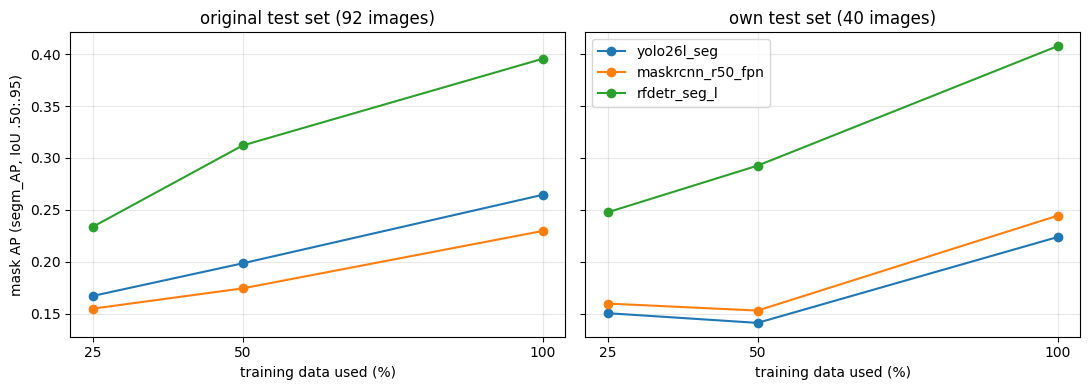

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (set_name, df) in zip(axes, summaries.items()):
    for k in MODELS:
        d = df[df.model == k].sort_values("train_fraction")
        ax.plot(d.train_fraction * 100, d.segm_AP, marker="o", label=k)
    ax.set_title(f"{set_name} test set ({int(df.num_images.iloc[0])} images)")
    ax.set_xlabel("training data used (%)")
    ax.set_xticks([C.pct(f) for f in SPLITS])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mask AP (segm_AP, IoU .50:.95)")
axes[1].legend()
plt.tight_layout()
plt.savefig(EVAL_DIR / "ap_vs_train_fraction_both_test_sets.png", dpi=150)
plt.show()

## Notes for reading the results

- **Own test set labels** were made with SAM2 assistance and revised manually in Roboflow, with the same 74 classes as
  the dataset.
- **Stuff classes** (wall, floor and so on) are labelled as one instance per separate region, like the source
  dataset. A model that predicts one large floor mask is matched to only one of those regions, which lowers
  `segm_AP_stuff`. Compare `segm_AP_thing` for objects.
- **Own test photos** are evaluated at long side 1280 px, so the COCO small, medium and large area buckets
  (`APs`, `APm`, `APl`) are not comparable with the 640x480 images of the original test set.
- **fps** includes the training code's pre and post processing on the local GPU (RTX 4060 Laptop), not the Kaggle T4.
- Drawn images only show detections with score >= `VIS_THRESH`. The metrics use all detections >= 0.001.